# 01 · Images, masks, coordinates, and annotation rules

**Level:** beginner · **Study time:** 45–60 minutes · **Prerequisite:** lesson 00.

**Build:** a small image/mask inspection and export pipeline. **Learn:** shapes, dtypes, coordinate
order, binary versus multiclass labels, correct resizing, overlays, and annotation consistency.
The default cells are fully runnable. Edit the experiment parameters, inspect the plots, then try
the exercises before opening their answers.


In [1]:
from pathlib import Path
import sys
PROJECT_ROOT = next(
    (p for p in [Path.cwd(), *Path.cwd().parents]
     if (p / "learning" / "data.py").is_file()), None
)
if PROJECT_ROOT is None:
    raise FileNotFoundError("Open this notebook inside the complete ImageSegmentationPractical folder.")
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))
import numpy as np
import matplotlib.pyplot as plt
plt.rcParams.update({"figure.figsize": (10, 3.5), "image.cmap": "gray",
                     "axes.spines.top": False, "axes.spines.right": False})
print("Project:", PROJECT_ROOT.name)


Project: ImageSegmentationPractical


## 1. An image is an array; a mask is a decision per pixel

We use RGB images shaped `(height, width, channels)` and integer masks shaped `(height, width)`.
Pixel values here are floating point numbers in `[0, 1]`. Other libraries may return unsigned
8-bit integers in `[0, 255]`. The scale matters to thresholds and neural network preprocessing.
A three-channel image is not three images: its last axis stores red, green, and blue.


RGB: (128, 128, 3) float32 range: (0.0, 1.0)
Mask: (128, 128) uint8 IDs: [0 1 2]


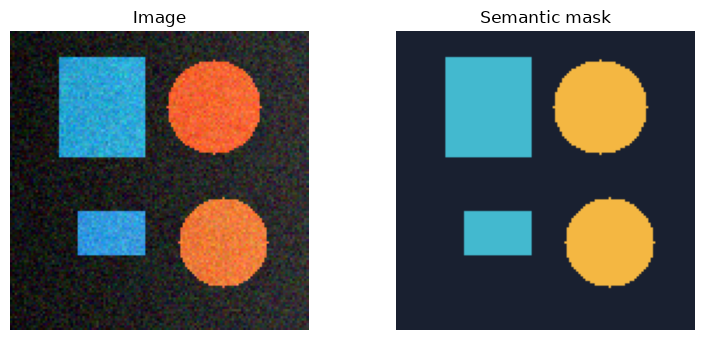

In [2]:
from learning.data import make_scene, palette_mask, CLASS_NAMES
image, mask, instance_mask = make_scene(seed=12, size=128)
assert image.shape[:2] == mask.shape
assert image.shape[-1] == 3 and image.dtype == np.float32
assert set(np.unique(mask)).issubset({0, 1, 2})
print("RGB:", image.shape, image.dtype, "range:", (float(image.min()), float(image.max())))
print("Mask:", mask.shape, mask.dtype, "IDs:", np.unique(mask))
fig, axes = plt.subplots(1, 2, figsize=(8, 3.5))
axes[0].imshow(image); axes[0].set_title("Image")
axes[1].imshow(palette_mask(mask)); axes[1].set_title("Semantic mask")
for ax in axes: ax.axis("off")
plt.tight_layout(); plt.show()


## 2. Index `[row, column]`, plot `(x, y)`

Rows move downward, columns move rightward. Array access uses `image[y, x]`, while plotting a
point uses `scatter(x, y)`. Mixing them often produces a plausible-looking annotation in the
wrong location. The slice end is excluded: rows `20:60` contain 40 pixels.


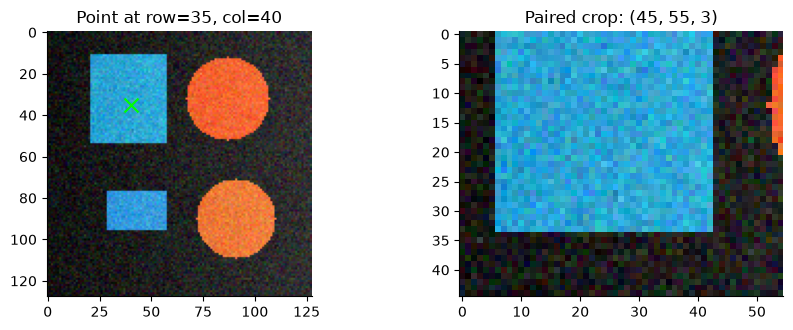

RGB at point: [0.06566297 0.6117452  0.79038745] | Class: rectangle


In [3]:
row, col = 35, 40
fig, axes = plt.subplots(1, 2, figsize=(9, 3.4))
axes[0].imshow(image); axes[0].scatter([col], [row], c="lime", marker="x", s=100)
axes[0].set_title(f"Point at row={row}, col={col}")
crop = image[20:65, 15:70]
mask_crop = mask[20:65, 15:70]
axes[1].imshow(crop); axes[1].set_title(f"Paired crop: {crop.shape}")
plt.tight_layout(); plt.show()
print("RGB at point:", image[row, col], "| Class:", CLASS_NAMES[mask[row, col]])
assert crop.shape[:2] == mask_crop.shape


## 3. Label encodings are different contracts

A binary mask says whether a pixel is foreground. A semantic mask chooses one category; class 0
is real background, not “unknown.” An instance mask identifies individual objects. A one-hot
mask adds a separate channel per class; exactly one channel is 1 at each valid pixel.
PyTorch multiclass cross-entropy expects integer class IDs, so you usually do **not** one-hot
encode its targets. Binary sigmoid models and multiclass softmax models use different loss contracts.


Binary: bool (128, 128)
Class IDs: uint8 (128, 128)
One-hot: float32 (128, 128, 3)
Instance IDs: [0 1 2 3 4]


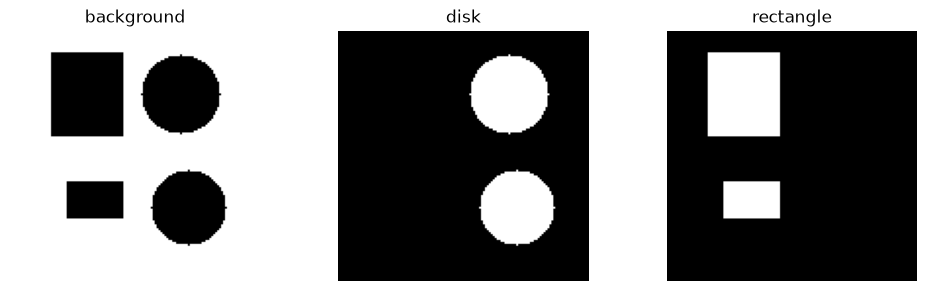

In [4]:
binary_mask = mask > 0
one_hot = np.eye(len(CLASS_NAMES), dtype=np.float32)[mask]
assert one_hot.shape == (*mask.shape, 3)
assert np.all(one_hot.sum(axis=-1) == 1)
assert np.array_equal(one_hot.argmax(axis=-1), mask)
print("Binary:", binary_mask.dtype, binary_mask.shape)
print("Class IDs:", mask.dtype, mask.shape)
print("One-hot:", one_hot.dtype, one_hot.shape)
print("Instance IDs:", np.unique(instance_mask))
fig, axes = plt.subplots(1, 3, figsize=(10, 3))
for cls, ax in enumerate(axes):
    ax.imshow(one_hot[..., cls], vmin=0, vmax=1)
    ax.set_title(CLASS_NAMES[cls]); ax.axis("off")
plt.tight_layout(); plt.show()


## 4. Inspect class balance

Pixel accuracy can look good if background occupies most of an image. Count labels before
training. Also count images and objects: a million neighboring pixels are not a million
independent examples. Images from the same patient, video, or scene should share one split.


,class,pixels,fraction
0,background,11856,0.723633
1,disk,2386,0.145630
2,rectangle,2142,0.130737


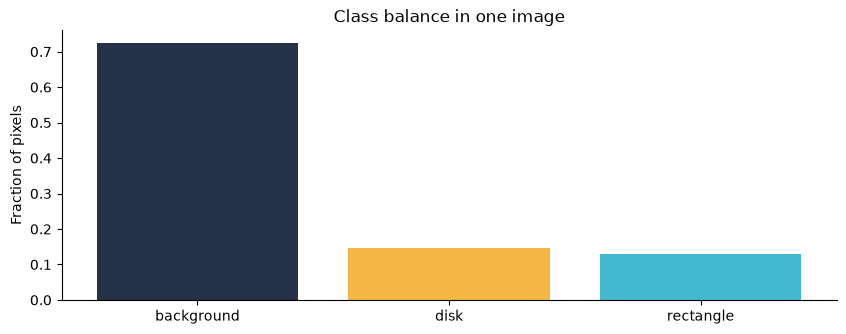

In [5]:
import pandas as pd
from IPython.display import display
counts = np.bincount(mask.ravel(), minlength=3)
balance = pd.DataFrame({"class": CLASS_NAMES, "pixels": counts,
                        "fraction": counts / mask.size})
display(balance)
plt.bar(CLASS_NAMES, counts / mask.size, color=["#253049", "#f4b742", "#43b9cf"])
plt.ylabel("Fraction of pixels"); plt.title("Class balance in one image"); plt.show()


## 5. Resize images smoothly and masks categorically

Bilinear interpolation blends neighboring values. That is useful for RGB images, but blending
class 0 and class 2 creates values that do not represent annotations. Casting blended values
back to integers can invent class 1. Use **nearest-neighbor** interpolation for class masks.
Keep the image and mask geometrically aligned, including during crops, flips, and rotations.


Nearest-neighbor IDs: [0 1 2]
Fractional label pixels with bilinear: 247


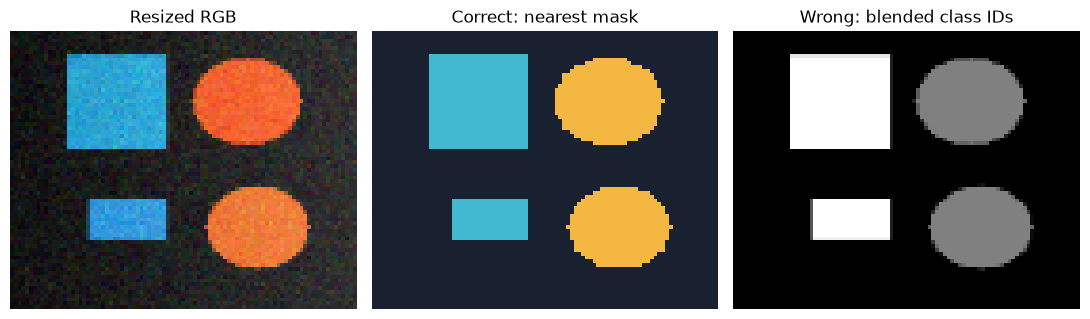

In [6]:
from skimage.transform import resize
target_shape = (73, 91)
resized_image = resize(image, (*target_shape, 3), order=1, anti_aliasing=True,
                       preserve_range=True).astype(np.float32)
good_mask = resize(mask, target_shape, order=0, anti_aliasing=False,
                   preserve_range=True).astype(np.uint8)
bad_mask = resize(mask.astype(float), target_shape, order=1,
                  anti_aliasing=False, preserve_range=True)
print("Nearest-neighbor IDs:", np.unique(good_mask))
print("Fractional label pixels with bilinear:", np.count_nonzero(bad_mask != np.round(bad_mask)))
assert set(np.unique(good_mask)).issubset(set(np.unique(mask)))
fig, axes = plt.subplots(1, 3, figsize=(11, 3.2))
for ax, arr, title in zip(axes, [resized_image, palette_mask(good_mask), bad_mask],
                          ["Resized RGB", "Correct: nearest mask", "Wrong: blended class IDs"]):
    ax.imshow(arr); ax.set_title(title); ax.axis("off")
plt.tight_layout(); plt.show()


## 6. Use overlays to audit alignment

An alpha overlay blends the image and display colors, while boundaries expose subtle shifts.
The overlay is for a person to inspect; save the original integer mask for training. Below we
deliberately shift one mask to show the kind of bug that numerical shape checks cannot catch.


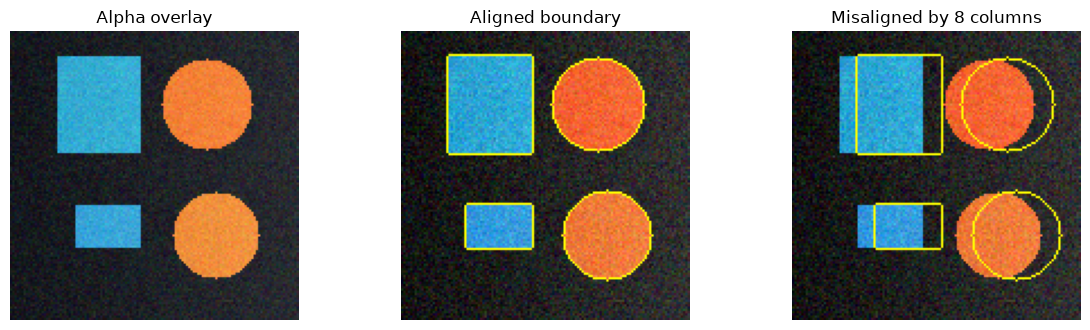

In [7]:
from skimage.segmentation import mark_boundaries
shifted_mask = np.roll(mask, shift=8, axis=1)  # Intentional demonstration bug.
overlay = .65 * image + .35 * (palette_mask(mask) / 255.0)
fig, axes = plt.subplots(1, 3, figsize=(12, 3.4))
for ax, arr, title in zip(axes,
    [overlay, mark_boundaries(image, mask), mark_boundaries(image, shifted_mask)],
    ["Alpha overlay", "Aligned boundary", "Misaligned by 8 columns"]):
    ax.imshow(arr); ax.set_title(title); ax.axis("off")
plt.tight_layout(); plt.show()


## 7. Export labels without destroying them

JPEG compression changes pixels, so do not use JPEG for label masks. Store these small class IDs
as an 8-bit grayscale PNG. Store RGB previews separately. For any ID above 255, choose a suitable
16-bit format or NumPy array and verify round trips. A palette PNG can store IDs despite looking
colorful: blindly converting it to RGB can lose the original class encoding.


In [8]:
from PIL import Image
output_dir = PROJECT_ROOT / "artifacts" / "01_masks"
output_dir.mkdir(parents=True, exist_ok=True)
Image.fromarray((image * 255).round().astype(np.uint8)).save(output_dir / "image.png")
Image.fromarray(mask).save(output_dir / "mask_ids.png")
Image.fromarray(palette_mask(mask)).save(output_dir / "mask_preview.png")
with Image.open(output_dir / "mask_ids.png") as saved:
    loaded_mask = np.asarray(saved)
assert loaded_mask.shape == mask.shape
assert np.array_equal(loaded_mask, mask)
print("Exact label round trip passed:", output_dir / "mask_ids.png")


Exact label round trip passed: C:\Users\Hareram ray\AI\ImageSegmentationPractical\artifacts\01_masks\mask_ids.png


## 8. Annotate a polygon and define unknown pixels

Real annotations require a written labeling policy: which objects count, whether holes count as
background, how to handle occlusion, and what to do with uncertain boundaries. Here a coarse
polygon simulates one manual annotation. It is deliberately approximate. A label such as **255**
may mean “ignore during loss and metrics,” but only if the data loader, loss, and evaluator agree.
Never silently convert unknown pixels into background.


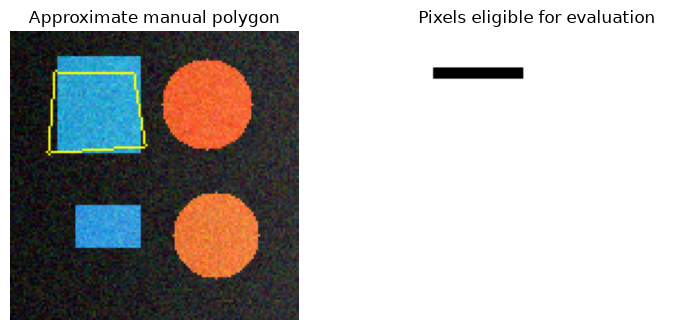

Ignored pixels: 200


In [9]:
from skimage.draw import polygon
polygon_y = np.array([18, 19, 50, 53])
polygon_x = np.array([20, 54, 59, 17])
rr, cc = polygon(polygon_y, polygon_x, shape=mask.shape)
manual_mask = np.zeros_like(mask)
manual_mask[rr, cc] = 1
uncertain_mask = manual_mask.copy()
uncertain_mask[16:21, 18:58] = 255
valid = uncertain_mask != 255
fig, axes = plt.subplots(1, 2, figsize=(8, 3.4))
axes[0].imshow(mark_boundaries(image, manual_mask)); axes[0].set_title("Approximate manual polygon")
axes[1].imshow(valid); axes[1].set_title("Pixels eligible for evaluation")
for ax in axes: ax.axis("off")
plt.tight_layout(); plt.show()
print("Ignored pixels:", (~valid).sum())


## 9. Exercises

1. Flip both image and mask horizontally and plot their boundary overlay. Then intentionally flip
   only the image. Which shape checks detect this error? Which visual check does?
2. Create a binary mask for disks only. Count its foreground pixels and verify against the table.
3. Downsample to 32×32 and upsample to the original size using nearest-neighbor masks. Calculate
   how many labels changed. Does correct interpolation guarantee no information loss?
4. Write a five-sentence annotation policy for segmenting leaves in photographs: target, background,
   occlusion, uncertain pixels, and train/validation/test grouping.

<details><summary>Worked solution code and guidance</summary>

```python
flipped_image = np.flip(image, axis=1).copy()
flipped_mask = np.flip(mask, axis=1).copy()
plt.imshow(mark_boundaries(flipped_image, flipped_mask)); plt.show()
# Shapes still match if only one is flipped. Inspect the overlay to catch the mismatch.
disk_mask = mask == 1
assert disk_mask.sum() == counts[1]
small = resize(mask, (32, 32), order=0, preserve_range=True, anti_aliasing=False)
restored = resize(small, mask.shape, order=0, preserve_range=True, anti_aliasing=False)
print("Changed labels:", np.count_nonzero(restored != mask))
```

Nearest-neighbor preserves the vocabulary of IDs, but downsampling can remove small objects and
boundary detail. A leaf policy might label visible leaf tissue, exclude stems, annotate only visible
parts under occlusion, ignore uncertain edges, and keep all pictures of a plant in one data split.
Different tasks may need different policies; consistency matters more than this particular choice.

</details>


## Checkpoint and common mistakes

- [ ] I can state the shape, dtype, scale, and label vocabulary of an image/mask pair.
- [ ] I can distinguish `[row, column]` indexing from `(x, y)` plotting.
- [ ] I resize class masks with nearest-neighbor and audit paired geometry visually.
- [ ] I save integer IDs separately from colored previews and test an exact round trip.
- [ ] I can explain background versus an ignored pixel.

**Watch for:** RGB versus OpenCV's usual BGR order; unsigned integer subtraction wrapping around;
lossy mask files; image and mask paths sorted differently; display colors mistaken for class IDs.
Use matching file stems and explicit label maps in lesson 10.

**References:** [NumPy indexing](https://numpy.org/doc/stable/user/basics.indexing.html),
[scikit-image resize](https://scikit-image.org/docs/stable/api/skimage.transform.html#skimage.transform.resize),
[Pillow image modes](https://pillow.readthedocs.io/en/stable/handbook/concepts.html#modes).

**Next:** [02 · Thresholding](02_thresholding.ipynb).
